# YOLO-World v2: 


In [29]:
from ultralytics import YOLOWorld

In [30]:
# Load the deployed YOLOv8s-worldv2 model
model = YOLOWorld("models/yolov8s-worldv2.pt")

In [ ]:
# Set custom open-vocabulary classes before inference
model.set_classes(["person", "bus", "sign"])

In [ ]:
# Run inference
results = model("data/smoke_images/bus.jpg", conf=0.25, iou=0.45, imgsz=640)


image 1/1 c:\Users\thepi\Documents\GitHub\CS-117-Insect-Detection\data\smoke_images\bus.jpg: 640x480 4 persons, 1 bus, 28.8ms
Speed: 3.2ms preprocess, 28.8ms inference, 2.0ms postprocess per image at shape (1, 3, 640, 480)


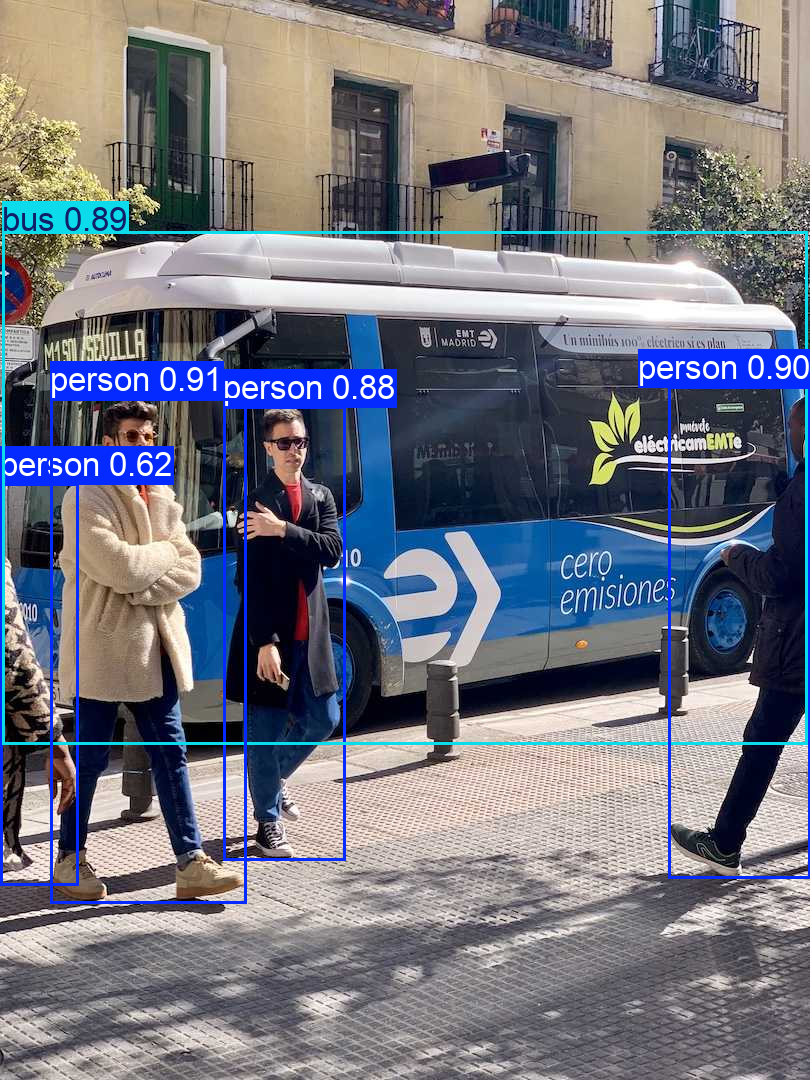

In [33]:
results[0].plot(pil=True)

# Insect Smoke Test


image 1/1 c:\Users\thepi\Documents\GitHub\CS-117-Insect-Detection\data\smoke_images\insect_img1.jpg: 640x480 1 pest, 10.9ms
Speed: 1.1ms preprocess, 10.9ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 480)

image 1/1 c:\Users\thepi\Documents\GitHub\CS-117-Insect-Detection\data\smoke_images\insect_img2.jpg: 640x480 (no detections), 19.6ms
Speed: 1.4ms preprocess, 19.6ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 480)

image 1/1 c:\Users\thepi\Documents\GitHub\CS-117-Insect-Detection\data\smoke_images\insect_img3.jpg: 640x480 2 pests, 13.3ms
Speed: 1.6ms preprocess, 13.3ms inference, 2.3ms postprocess per image at shape (1, 3, 640, 480)

image 1/1 c:\Users\thepi\Documents\GitHub\CS-117-Insect-Detection\data\smoke_images\insect_img4.jpg: 640x480 1 pest, 10.8ms
Speed: 1.5ms preprocess, 10.8ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 480)

image 1/1 c:\Users\thepi\Documents\GitHub\CS-117-Insect-Detection\data\smoke_images\insect_img5.jpg: 

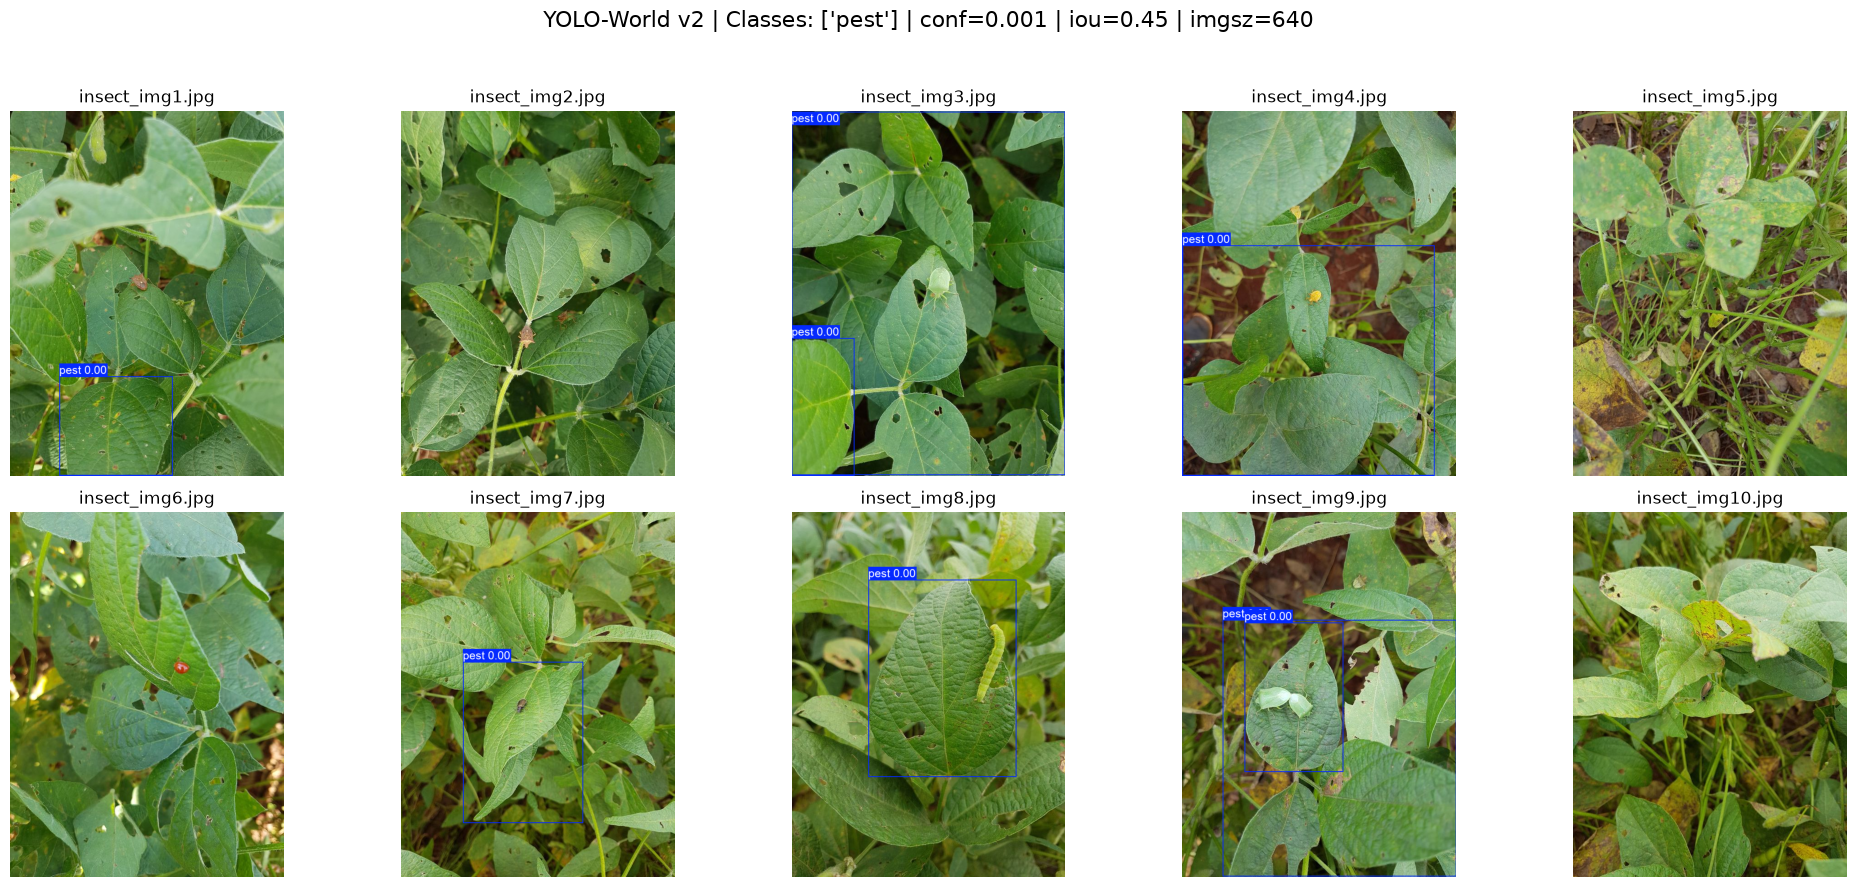

In [37]:
import matplotlib.pyplot as plt

# Load the pretrained model and ask it to look for insects.
model = YOLOWorld("models/yolov8s-worldv2.pt")
classes=["pest"]
model.set_classes(classes)

# conf: Minimum confidence score required to keep a detection.
# Lower = more detections, but potentially more false alarms.
# This score is not a calibrated probability that the box is correct.
confidence_threshold = 0.001

# iou: Box-overlap cutoff used by non-maximum suppression (NMS).
# NMS removes lower-scoring, overlapping boxes to reduce duplicates.
# Lower = more aggressive removal; this can also hide overlapping insects.
# This setting is separate from the IoU threshold used to evaluate AP.
overlap_threshold = 0.45

# imgsz: Target input size in pixels; YOLO resizes/pads the image
# while preserving its aspect ratio, so the input can be rectangular.
# Larger values may help with small insects, but use more time and memory.
image_size = 640

# Make a grid with 2 rows and 5 columns: one panel for each image.
figure, axes = plt.subplots(nrows=2, ncols=5, figsize=(20, 9))
figure.suptitle(
    f"YOLO-World v2 | Classes: {classes} | conf={confidence_threshold} | "
    f"iou={overlap_threshold} | imgsz={image_size}",
    fontsize=16,
)

# axes.flat lets us visit each panel in the grid, one at a time.
for image_number, axis in enumerate(axes.flat, start=1):
    image_path = f"data/smoke_images/insect_img{image_number}.jpg"

    # Run the detector on this image using the settings above.
    results = model(
        image_path,
        conf=confidence_threshold,
        iou=overlap_threshold,
        imgsz=image_size,
    )

    # We passed one image, so its prediction is the first result: [0].
    # plot() draws the predicted boxes, labels, and confidence scores.
    annotated_image = results[0].plot(pil=True)
    axis.imshow(annotated_image)
    axis.set_title(f"insect_img{image_number}.jpg")
    axis.axis("off")  # Hide the plot's coordinate axes.

# Leave room for the heading and display the completed grid.
figure.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()



image 1/1 c:\Users\thepi\Documents\GitHub\CS-117-Insect-Detection\data\smoke_images\bus.jpg: 640x480 3 pests, 10.6ms
Speed: 1.9ms preprocess, 10.6ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 480)


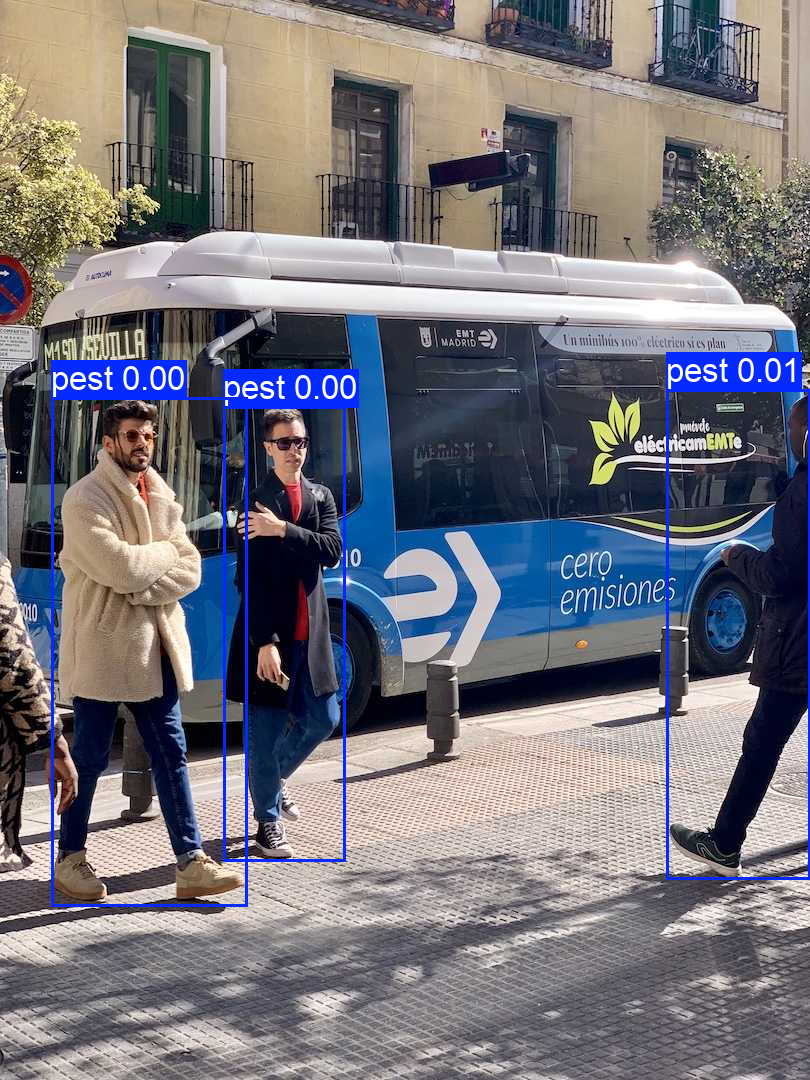

In [40]:
# Load the deployed YOLOv8s-worldv2 model
model = YOLOWorld("models/yolov8s-worldv2.pt")
# Set custom open-vocabulary classes before inference
model.set_classes(classes)
# Run inference
results = model("data/smoke_images/bus.jpg", conf=0.001, iou=0.45, imgsz=640)
results[0].plot(pil=True)